# 05 · Real microscope: step-by-step tests

Run this on the real microscope **from top to bottom, one section at a time**. Each level builds on the one before:

| Level | What | Moves the microscope? |
|---|---|---|
| 0 | Setup and safety switches | no |
| 1 | MCP, data and timing | no (takes images) |
| 2 | Individual nodes | only with `ALLOW_STAGE` |
| 3 | Instrument checks: metric response, corrector sign, beam x/y order | with `ALLOW_STAGE` / `ALLOW_CORRECTOR` / `ALLOW_BEAM` |
| 4 | Tuning nodes: focus z, C1, A1 | with `ALLOW_STAGE` / `ALLOW_CORRECTOR` |
| 5 | Segmentation and EDS | EDS with `ALLOW_BEAM` |
| 6 | Build your own graph | depends on the nodes you put in |
| 7 | Full run | all switches |

**Nothing moves unless you switch it on in the first cell.** A gated cell prints `SKIPPED` when its switch is off, so "Run All" is safe.

**Before you start**
- The asyncroscopy MCP server for the microscope is running, and `STEM_REAL_MCP_URL` is set in `.env`.
- Scan size, dwell time and EDS exposure are set by hand (not reachable through MCP yet).
- Dry run first: set `INSTRUMENT = "twin"` and start the twin (`uv run python scripts/twin.py start`). The whole notebook runs on the twin too.

## Level 0 · Setup and safety switches

In [1]:
INSTRUMENT = "real"            # "real", or "twin" for a dry run

# Safety switches: nothing moves unless switched on here
ALLOW_STAGE = True        # stage moves: move node, z response, focus z
ALLOW_CORRECTOR = True    # corrector changes: C1 / A1 response, sign check, tune C1 / A1
ALLOW_BEAM = True         # park the beam and take EDS spectra

# Small, careful settings for a first session (defaults in stem_agent/config.py are larger)
TEST_TUNING = {
    "z":  {"step_m": 1e-6, "max_offset_m": 20e-6,  "max_iterations": 20},
    "C1": {"step_m": 5e-9,   "max_offset_m": 20e-9, "max_iterations": 20},
    "A1": {"step_m": 1e-9,   "max_offset_m": 4e-9,  "max_iterations": 20},
}
TUNING_FOV_M = 186e-9 if INSTRUMENT == "real" else 40e-9   # tuning, overview, segmentation
MAX_EDS_POINTS = 3

In [2]:
%matplotlib inline
import json
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Image, display

from stem_agent.analysis.metrics import METRICS, all_metrics
from stem_agent.analysis.segmentation import pixel_size_m, sam_particles, segment
from stem_agent.config import INSTRUMENTS, TOOLS
from stem_agent.data import tiled_io
from stem_agent.mcp import session
from stem_agent.nodes import common
from stem_agent.nodes.eds_node import eds_node
from stem_agent.nodes.move_stage_node import move_stage_node, undo_move
from stem_agent.nodes.overview_node import overview_node
from stem_agent.nodes.preflight_node import preflight_node
from stem_agent.nodes.save_node import save_node
from stem_agent.nodes.sam_segment_node import sam_segment_node
from stem_agent.nodes.set_fov_node import set_fov_node, undo_fov
from stem_agent.nodes.status_node import device_state, normalize_parameters, status_node
from stem_agent.nodes.tune_node import Corrector, StageZ, tune_node
from stem_agent.utils.plots import plot_graph, plot_particles


def allowed(flag, what):
    """Gate for cells that change the microscope."""
    if not flag:
        print(f"SKIPPED: {what}. Switch it on in the first cell to run it.")
    return flag


def apply(state, update):
    """Merge a node's update into a new state dict (errors and tuning add up, as in the graph)."""
    print("->", sorted(update), "| run_status:", update.get("run_status", state.get("run_status")))
    for error in update.get("errors", []):
        print("ERROR:", error)
    merged = {**state, **update}
    if "errors" in update:
        merged["errors"] = state.get("errors", []) + update["errors"]
    if "tuning" in update:
        merged["tuning"] = {**state.get("tuning", {}), **update["tuning"]}
    return merged


def one_step(state, name):
    """The state for running one protocol step by name, again if it was done (notebook use)."""
    step = next(s for s in state["settings"]["protocol"] if s["name"] == name)
    return {**state, "settings": {**state["settings"], "protocol": [step]}, "tuning": {}}


def protocol_step(state, name):
    """The protocol step with this name; edit it in place to change that step's next run."""
    return next(s for s in state["settings"]["protocol"] if s["name"] == name)


def show(images, titles):
    fig, axes = plt.subplots(1, len(images), figsize=(5 * len(images), 5), squeeze=False)
    for ax, image, title in zip(axes[0], images, titles):
        ax.imshow(image, cmap="gray")
        ax.set_title(title)
        ax.axis("off")
    plt.show()


print(f"instrument {INSTRUMENT} | stage {ALLOW_STAGE} | corrector {ALLOW_CORRECTOR} | beam {ALLOW_BEAM}")

target real | stage True | corrector True | beam True


## Level 1 · MCP, data and timing (nothing moves)

### 1.1 Connect and check the tools
Every short name in `config.TOOLS` must exist on the server. Tool names are `<TangoClass>_<command>`.

In [3]:
url = INSTRUMENTS[INSTRUMENT]["mcp_url"]
if not url:
    raise SystemExit("No MCP URL: set STEM_REAL_MCP_URL in .env and restart the kernel")
client = session.connect(INSTRUMENT)
tools = await client.list_tools()
print(f"{url}: {len(tools)} tools")
missing = []
for short in TOOLS:
    name = session.tool_name(short)
    tool = tools.get(name)
    args = ", ".join((tool.inputSchema or {}).get("properties", {})) if tool else ""
    print(f"  {'ok     ' if tool else 'MISSING'} {short:<20} {name}({args})")
    if tool is None:
        missing.append(short)
print("missing:", missing or "none")

http://10.46.217.241:8000/mcp: 71 tools
  ok      list_devices         list_devices()
  ok      get_tiled_config     DATA_get_config()
  ok      get_stage            AutoScriptMicroscope_get_stage()
  ok      move_stage           AutoScriptMicroscope_move_stage(position)
  ok      get_fov              AutoScriptMicroscope_get_fov()
  ok      set_fov              AutoScriptMicroscope_set_fov(fov)
  ok      get_defocus          AutoScriptMicroscope_get_defocus()
  ok      get_parameters       AutoScriptMicroscope_get_parameters()
  ok      acquire_image        AutoScriptMicroscope_acquire_scanned_image(detector_list)
  ok      acquire_spectrum     AutoScriptMicroscope_acquire_spectrum(detector_name)
  ok      place_beam           AutoScriptMicroscope_place_beam(position)
  ok      blank_beam           AutoScriptMicroscope_blank_beam()
  ok      correct_aberration   CEOSCorrector_correct_aberration(args)
  ok      corrector_info       CEOSCorrector_get_info()
missing: none


### 1.2 If tools are missing: which Tango classes does the server have?
If the class names differ from `INSTRUMENTS[INSTRUMENT]`, fix them here (and later in `stem_agent/config.py`), then re-run 1.1.

In [4]:
for command in ("acquire_scanned_image", "move_stage", "correct_aberration"):
    owners = [t.removesuffix("_" + command) for t in tools if t.endswith("_" + command)]
    print(f"{command:<24} offered by {owners}")
print("configured:", {k: INSTRUMENTS[INSTRUMENT][k] for k in ("microscope", "corrector")})
# e.g. INSTRUMENTS[INSTRUMENT]["corrector"] = "CEOSCorrector"

acquire_scanned_image    offered by ['AutoScriptMicroscope']
move_stage               offered by ['AutoScriptMicroscope']
correct_aberration       offered by ['CEOSCorrector']
configured: {'microscope': 'AutoScriptMicroscope', 'corrector': 'CEOSCorrector'}


### 1.3 Read-only status
Check:
- **alpha**: if it reads `nan`, the 2.4 round-trip test matters.
- **`get_parameters` keys**: the status node reads `optical_mode`, `beam_blanker`, `column_valves`, `is_accelerator_on` and `beam_stopper`. A missing key means "unknown", and on the real microscope unknown stops the run.
- **device states**: each should be `ON`.

In [5]:
stage = await common.get_stage()
fov = await session.call("get_fov")
defocus = await session.call("get_defocus")
print("stage [x, y, z, alpha, beta]:", stage, "| alpha is NaN:", np.isnan(stage[3]))
print(f"FOV {fov * 1e9:.1f} nm | defocus {defocus}")

try:
    params = await session.call("get_parameters")
    params = json.loads(params) if isinstance(params, str) else params
    print("get_parameters keys:", sorted(params))
    print("normalized for the status node:", normalize_parameters(params))
except Exception as exc:
    print("get_parameters FAILED:", exc)
    print("-> the status node cannot confirm readiness; fix this in asyncroscopy before a full run")

for tool in sorted(t for t in tools if t.endswith("_State")):
    print(f"  {tool.removesuffix('_State'):<24} {device_state(await session.call_tool(tool))}")

stage [x, y, z, alpha, beta]: [-3.2797124731587246e-05, 4.745680053019896e-05, 7.656669185962528e-05, 0.005676178261637688, 0.0] | alpha is NaN: False
FOV 3009.0 nm | defocus 7.072345908909483e-08
get_parameters keys: ['BeamShift', 'BeamTilt', 'C1', 'C2', 'C3', 'GunShift', 'GunTilt', 'ImageShift', 'ImageTilt', 'Objective', 'SA', 'acceleration_voltage', 'beam_blanker', 'beam_stopper', 'column_valves', 'illumination_mode', 'is_accelerator_on', 'is_eftem_on', 'objective_lens_mode', 'optical_mode', 'projector_mode', 'scan_field_of_view', 'scan_rotation', 'spot_size', 'system', 'vacuum']
opened
normalized for the status node: {'stem_mode': True, 'beam_blanked': False, 'column_valves_open': True, 'high_tension_on': True, 'beam_stopper_out': True}
  AutoScriptMicroscope     ON
  AutoScriptSTAGE          ON
  CAMERA                   ON
  CEOSCorrector            ON
  DATA                     ON
  EDS                      ON
  EELS                     ON
  SCAN                     ON


### 1.4 Tiled and one HAADF image
MCP returns the Tiled key; the full image comes from Tiled over HTTP.

Tiled http://10.46.217.241:9091 | key stem_image_HAADF_20261105T161010635639.h5 | (512, 512) float64 | 2.6 s
{'contrast': 0.2435, 'edge_sharpness': 0.1412, 'entropy': 0.8574, 'high_frequency_power': 0.251}


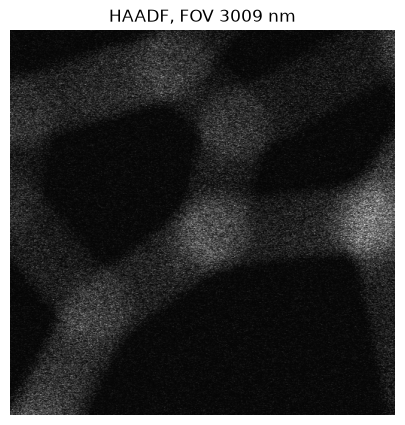

In [6]:
uri = json.loads(await session.call("get_tiled_config"))["uri"]
tiled_io.connect(uri)
t0 = time.time()
key, image = await common.acquire_haadf()
print(f"Tiled {uri} | key {key} | {image.shape} {image.dtype} | {time.time() - t0:.1f} s")
print({name: round(value, 4) for name, value in all_metrics(image).items()})
show([image], [f"HAADF, FOV {fov * 1e9:.0f} nm"])

In [19]:
tools = await client.list_tools()

In [20]:
tools

{'get_data_from_key': Tool(name='get_data_from_key', title='Get Data From Key', description='Read a remote DATA/Tiled key and return dataset metadata plus small previews.', inputSchema={'properties': {'key': {'type': 'string'}, 'max_values': {'default': 64, 'type': 'integer'}, 'data_device_address': {'anyOf': [{'type': 'string'}, {'type': 'null'}], 'default': None}}, 'required': ['key'], 'type': 'object', 'additionalProperties': False}, outputSchema={'type': 'object', 'additionalProperties': True}, icons=None, annotations=None, meta={'fastmcp': {'tags': []}}, execution=None),
 'list_devices': Tool(name='list_devices', title='List Devices', description='List available devices filtered by blocked classes.', inputSchema={'properties': {}, 'type': 'object', 'additionalProperties': False}, outputSchema={'properties': {'result': {'items': {'type': 'string'}, 'type': 'array'}}, 'required': ['result'], 'type': 'object', 'x-fastmcp-wrap-result': True}, icons=None, annotations=None, meta={'fastm

### 1.5 Timing
MCP gives each command 30 s on the server side. Acquisitions must stay well below that.

In [28]:
times = []
for _ in range(3):
    t0 = time.time()
    await common.acquire_haadf()
    times.append(time.time() - t0)
print(f"HAADF: {np.mean(times):.1f} s per image (min {min(times):.1f}, max {max(times):.1f}); limit 30 s")

HAADF: 2.0 s per image (min 1.7, max 2.2); limit 30 s


## Level 2 · Individual nodes
Each node runs alone on a state built by hand, exactly as the graph will run it. `SETTINGS["stage_xy_m"]` is the **current** position, so nothing moves by accident.

In [46]:
TEST_TUNING = {
    "z":  {"step_m": 10e-6, "max_offset_m": 300e-6,  "max_iterations": 30},
    "C1": {"step_m": 10e-9,   "max_offset_m": 200e-9, "max_iterations": 30},
    "A1": {"step_m": 1e-9,   "max_offset_m": 4e-9,  "max_iterations": 30},
}
TUNING_FOV_M = 100e-9 if INSTRUMENT == "real" else 40e-9   # tuning, overview, segmentation
MAX_EDS_POINTS = 3

In [47]:
x0, y0 = stage[0], stage[1]
SETTINGS = {
    "instrument": INSTRUMENT,
    "stage_xy_m": (x0, y0),          # stay where we are
    "tuning_fov_m": TUNING_FOV_M,
    "protocol": [                    # tuning steps, in order (values from TEST_TUNING)
        {"name": "z",  "tune": "z",  **TEST_TUNING["z"]},
        {"name": "C1", "tune": "C1", "fov_m": TUNING_FOV_M, **TEST_TUNING["C1"]},
        {"name": "A1", "tune": "A1", "fov_m": TUNING_FOV_M, **TEST_TUNING["A1"]},
    ],
    "max_particles": MAX_EDS_POINTS,
    "run_tag": "real_tests",
}
state = {"settings": SETTINGS}

In [50]:
state.keys()

dict_keys(['settings', 'run', 'run_status', 'errors', 'start', 'current', 'tuning', 'overview'])

In [51]:
state['tuning']

{'z': {'name': 'z',
  'settings': {'metric': 'contrast',
   'step_m': 1e-05,
   'max_offset_m': 0.0003,
   'max_iterations': 30},
  'best_offset_m': [-1.887237885966897e-07],
  'best_score': 0.27744759608478375,
  'n_images': 11,
  'stop_reason': 'converged',
  'best_image_key': 'stem_image_HAADF_20261105T170951235275.h5',
  'history_path': '/Users/borisslautin/Documents/GitHub/STEM_Particle_Analysis/runs/20261105_170941_real_tests/tune_z.json',
  'figure_path': '/Users/borisslautin/Documents/GitHub/STEM_Particle_Analysis/runs/20261105_170941_real_tests/tune_z.png'},
 'C1': {'name': 'C1',
  'settings': {'metric': 'contrast',
   'step_m': 2e-09,
   'max_offset_m': 2e-07,
   'max_iterations': 30},
  'best_offset_m': [-2e-09],
  'best_score': 0.161082559206423,
  'n_images': 10,
  'stop_reason': 'converged',
  'best_image_key': 'stem_image_HAADF_20261105T171114033824.h5',
  'history_path': '/Users/borisslautin/Documents/GitHub/STEM_Particle_Analysis/runs/20261105_170941_real_tests/tune_C1

[preflight] FAILED: tuning z: max_offset_m 0.0003 m is over half the per-move limit (5e-05 m)
-> ['errors', 'run', 'run_status'] | run_status: failed
ERROR: preflight: ValueError: tuning z: max_offset_m 0.0003 m is over half the per-move limit (5e-05 m)
opened
[status_start] stage [-3.4e-05, +4.69e-05, +6.74e-05, +0.00568, +0] | FOV 7.461555355803284e-07 m | devices 8 (all ON) | ready True
-> ['current', 'start'] | run_status: failed
[tune_z]  1 start offset [0.0] um  contrast 0.2707
[tune_z]  2 start offset [-10.003] um  contrast 0.086314
[tune_z]  3 start offset [10.003] um  contrast 0.093782
[tune_z]  4 model offset [0.301] um  contrast 0.26546
[tune_z]  5 model offset [-0.189] um  contrast 0.27745
[tune_z]  6 model offset [0.51] um  contrast 0.26897
[tune_z]  7 model offset [0.14] um  contrast 0.27236
[tune_z]  8 model offset [-0.084] um  contrast 0.27547
[tune_z]  9 model offset [0.084] um  contrast 0.27682
[tune_z] 10 model offset [0.049] um  contrast 0.27606
[tune_z] 11 model of

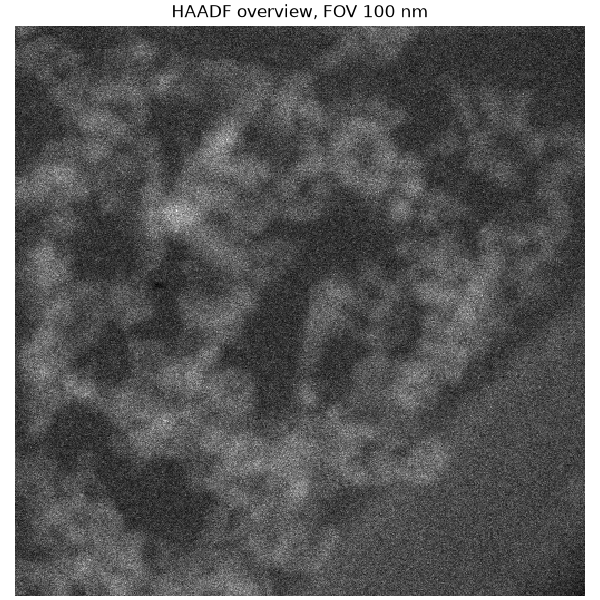

In [48]:
state = {"settings": SETTINGS}
state = apply(state, await preflight_node(state))       # 2.1
#protocol_step(state, "z")["step_m"] = 4e-6
state = apply(state, await status_node(state))    # 2.2 → first snapshot (gate) + 'current'

state = apply(state, await tune_node(one_step(state, "z"))) 

state = apply(state, await status_node(state))  
state = apply(state, await set_fov_node(state))

state = apply(state, await status_node(state))
state = apply(state, await tune_node(one_step(state, "C1")))

protocol_step(state, "C1")["step_m"] = 2e-9
state = apply(state, await status_node(state))

state = apply(state, await status_node(state))
state = apply(state, await tune_node(one_step(state, "C1")))

state = apply(state, await overview_node(state))
Image(state["overview"]["preview_path"])


In [ ]:
protocol_step(state, "C1")["step_m"] = 2e-9

{'z': {'step_m': 1e-05, 'max_offset_m': 5e-05, 'max_iterations': 20},
 'C1': {'step_m': 5e-09, 'max_offset_m': 4e-07, 'max_iterations': 20},
 'A1': {'step_m': 1e-09, 'max_offset_m': 4e-09, 'max_iterations': 20}}

[preflight] FAILED: tuning z: max_offset_m 5e-05 m is over half the per-move limit (5e-05 m)
-> ['errors', 'run', 'run_status'] | run_status: failed
ERROR: preflight: ValueError: tuning z: max_offset_m 5e-05 m is over half the per-move limit (5e-05 m)
opened
[status_start] stage [-3.29e-05, +4.75e-05, +6.77e-05, +0.00568, +0] | FOV 1.159444540377308e-08 m | devices 8 (all ON) | ready True
-> ['current', 'start'] | run_status: failed
[tune_C1]  1 start offset [0.0] nm  contrast 0.24868
[tune_C1]  2 start offset [-5.0] nm  contrast 0.25008
[tune_C1]  3 start offset [5.0] nm  contrast 0.24915
[tune_C1]  4 model offset [-10.0] nm  contrast 0.25573
[tune_C1]  5 model offset [-16.0] nm  contrast 0.25698
[tune_C1]  6 model offset [-23.2] nm  contrast 0.26041
[tune_C1]  7 model offset [-31.84] nm  contrast 0.25532
[tune_C1]  8 model offset [-24.52] nm  contrast 0.26242
[tune_C1]  9 model offset [-25.699] nm  contrast 0.26381
[tune_C1] 10 model offset [-27.721] nm  contrast 0.26309
[tune_C1] 11

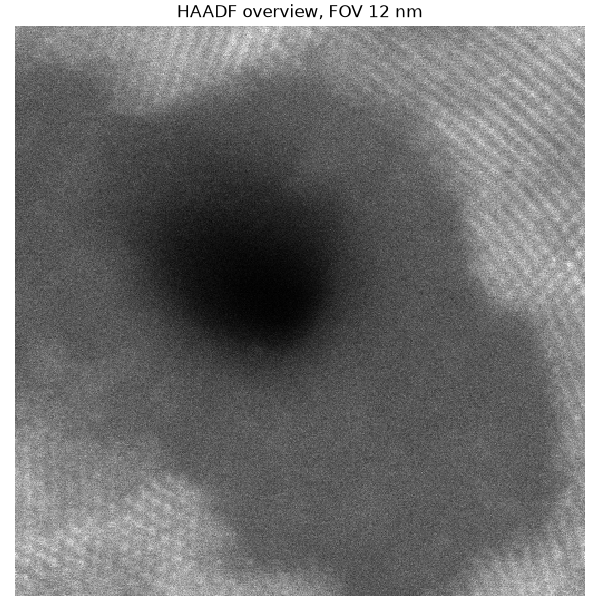

In [24]:
state = apply(state, await preflight_node(state))       # 2.1
state = apply(state, await status_node(state))
state = apply(state, await tune_node(one_step(state, "C1")))

state = apply(state, await overview_node(state))
Image(state["overview"]["preview_path"])

[overview] stem_image_HAADF_20261105T163221649777.h5 (512, 512) -> overview.png
-> ['overview'] | run_status: failed


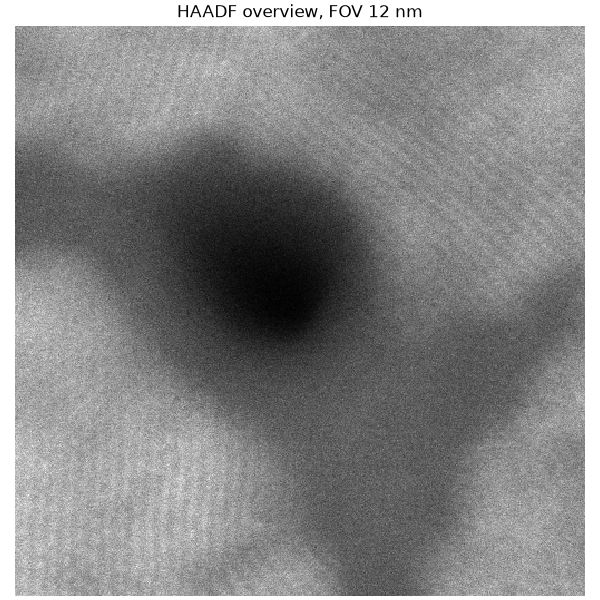

In [23]:
state = apply(state, await overview_node(state))
Image(state["overview"]["preview_path"])

In [32]:
state = apply(state, await status_node(state))
state = apply(state, await tune_node(one_step(state, "C1")))

opened
[status_start] stage [-3.07e-05, +4.85e-05, +6.76e-05, +0.00568, +0] | FOV 9.200000050668677e-08 m | devices 8 (all ON) | ready True
-> ['current', 'start'] | run_status: failed
[tune_C1]  1 start offset [0.0] nm  contrast 0.33523
[tune_C1]  2 start offset [-20.0] nm  contrast 0.33324
[tune_C1]  3 start offset [20.0] nm  contrast 0.33339
[tune_C1]  4 model offset [0.6] nm  contrast 0.33425
[tune_C1]  5 model offset [0.975] nm  contrast 0.33361
[tune_C1]  6 model offset [0.38] nm  contrast 0.33386
[tune_C1]  7 model offset [0.741] nm  contrast 0.33291
[tune_C1]  8 model offset [0.839] nm  contrast 0.33235
[tune_C1]  9 model offset [1.044] nm  contrast 0.33404
[tune_C1] 10 model offset [0.935] nm  contrast 0.33266
[tune_C1] best [0.0] nm, contrast 0.33523, 10 images, stop: converged
-> ['current', 'tuning'] | run_status: failed


opened
[status_start] stage [-3.07e-05, +4.85e-05, +6.76e-05, +0.00568, +0] | FOV 9.200000050668677e-08 m | devices 8 (all ON) | ready True
-> ['current', 'start'] | run_status: failed
[tune_A1]  1 start offset [0.0, 0.0] nm  contrast 0.32999
[tune_A1]  2 start offset [1.0, 0.0] nm  contrast 0.32927
[tune_A1]  3 start offset [0.707, 0.707] nm  contrast 0.32882
[tune_A1]  4 start offset [0.0, 1.0] nm  contrast 0.32964
[tune_A1]  5 start offset [-0.707, 0.707] nm  contrast 0.32956
[tune_A1]  6 start offset [-1.0, 0.0] nm  contrast 0.32997
[tune_A1]  7 start offset [-0.707, -0.707] nm  contrast 0.32969
[tune_A1]  8 start offset [-0.0, -1.0] nm  contrast 0.32988
[tune_A1]  9 start offset [0.707, -0.707] nm  contrast 0.32897
[tune_A1] 10 model offset [-0.375, -0.125] nm  contrast 0.32924
[tune_A1] 11 model offset [-0.601, -0.244] nm  contrast 0.32945
[tune_A1] 12 model offset [-0.401, -0.127] nm  contrast 0.32884
[tune_A1] 13 model offset [-0.261, -0.082] nm  contrast 0.32857
[tune_A1] 14 m

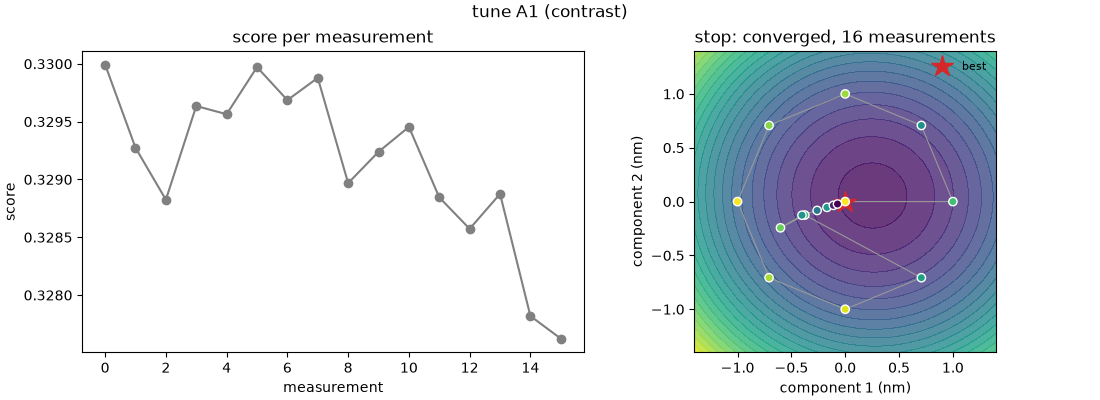

In [33]:
state = apply(state, await status_node(state))
state = apply(state, await tune_node(one_step(state, "A1")))
if "A1" in state.get("tuning", {}):
        display(Image(state["tuning"]["A1"]["figure_path"]))

[overview] stem_image_HAADF_20261105T155756832464.h5 (512, 512) -> overview.png
-> ['overview'] | run_status: failed


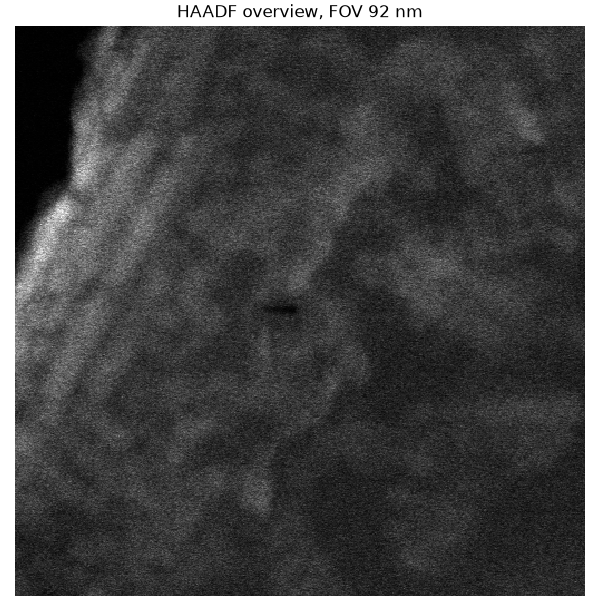

In [28]:
state = apply(state, await overview_node(state))
Image(state["overview"]["preview_path"])

### 2.1 Preflight
Expected: `run_status: running`, run folder created, settings checked.

In [9]:
state = apply(state, await preflight_node(state))
state["run"]["run_dir"]

[preflight] real at http://10.46.217.241:8000/mcp: 14/14 tools, Tiled http://10.46.217.241:9091, run folder /Users/borisslautin/Documents/GitHub/STEM_Particle_Analysis/runs/20261105_152221_real_tests
-> ['run', 'run_status'] | run_status: running


'/Users/borisslautin/Documents/GitHub/STEM_Particle_Analysis/runs/20261105_152221_real_tests'

### 2.2 Status: first snapshot (the readiness gate)
Expected: `ready: True`. **If not ready, stop here** and fix the microscope; the node never fixes anything itself.

In [31]:
state = apply(state, await status_node(state))
snap = state["snapshots"][0]
{k: snap[k] for k in ("stage", "fov_m", "stem_mode", "beam_blanked", "column_valves_open",
                      "high_tension_on", "beam_stopper_out", "devices", "ready", "problems", "warnings")}

opened
[status_start] stage [-2.85e-05, +4.87e-05, +5.94e-05, +0.00568, +0] | FOV 1.2036044608976226e-05 m | devices 8 (all ON) | ready True
-> ['current', 'start'] | run_status: running


{'stage': [-2.8496040613390505e-05,
  4.8720245104050264e-05,
  5.939925176789984e-05,
  0.005676178261637688,
  0.0],
 'fov_m': 1.2036044608976226e-05,
 'stem_mode': True,
 'beam_blanked': False,
 'column_valves_open': True,
 'high_tension_on': True,
 'beam_stopper_out': True,
 'devices': {'AutoScriptMicroscope': 'ON',
  'AutoScriptSTAGE': 'ON',
  'CAMERA': 'ON',
  'CEOSCorrector': 'ON',
  'DATA': 'ON',
  'EDS': 'ON',
  'EELS': 'ON',
  'SCAN': 'ON'},
 'ready': True,
 'problems': [],
 'warnings': []}

### 2.3 Overview (no motion)

[overview] stem_image_HAADF_20261105T150206919486.h5 (512, 512) -> overview.png
-> ['overview'] | run_status: running


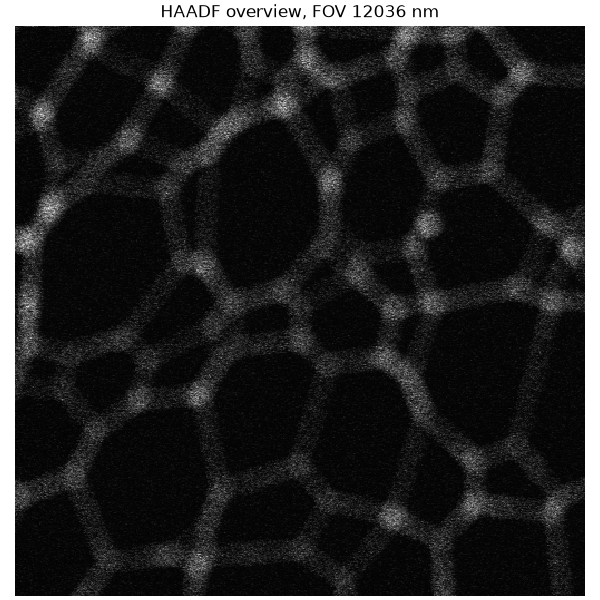

In [11]:
state = apply(state, await overview_node(state))
Image(state["overview"]["preview_path"])

### 2.4 Stage round trip without moving
Sends the stage position it just read back to `move_stage`. If alpha is `NaN` and that can't pass through MCP's JSON, the error shows up here, **without any motion**.

In [12]:
if allowed(ALLOW_STAGE, "stage round trip"):
    print("before:", await common.get_stage())
    print("after: ", await common.move_stage())     # no axis given: same position

before: [-2.8511189157143235e-05, 4.9242455133935437e-05, 7.586769061163068e-05, 0.005676178261637688, 0.0]
after:  [-2.8514219593489543e-05, 4.9243470130022615e-05, 7.586769061163068e-05, 0.005676178261637688, 0.0]


### 2.5 Move node: +50 nm in x, then undo
Expected: readback within 10 nm, image shifted by 50 nm, back at the start.

[move] (-28.5112, +49.2414) -> (-28.4612, +49.2384) um
-> ['current'] | run_status: running


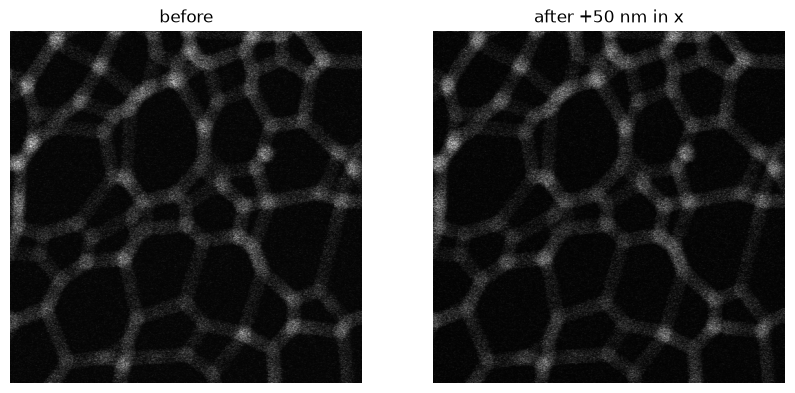

back at: [-2.851270437531639e-05, 4.9243470130022615e-05, 7.586769061163068e-05, 0.005676178261637688, 0.0]


In [13]:
if allowed(ALLOW_STAGE, "move node"):
    trial = {**state, "settings": {**SETTINGS, "stage_xy_m": (x0 + 50e-9, y0)}}
    _, before_image = await common.acquire_haadf()
    update = apply(trial, await move_stage_node(trial))
    _, after_image = await common.acquire_haadf()
    show([before_image, after_image], ["before", "after +50 nm in x"])
    await undo_move(trial)
    print("back at:", await common.get_stage())

### 2.6 Set FOV, then undo
Expected: readback within 1 %, wider view, back to the start FOV.

[set_fov] 12036.0 -> 186.0 nm
-> ['current'] | run_status: running
-> ['current'] | run_status: running


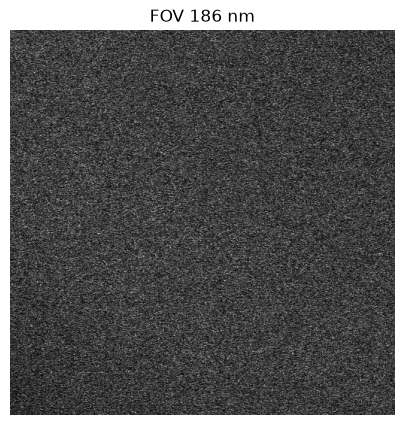

FOV back to 12036.0 nm


In [14]:
before = state
state = apply(state, await set_fov_node(state))
_, zoom_image = await common.acquire_haadf()
await undo_fov(before)
state = apply(state, {"current": {**state["current"], "fov_m": await session.call("get_fov")}})
show([zoom_image], [f"FOV {TUNING_FOV_M * 1e9:.0f} nm"])
print(f"FOV back to {state['current']['fov_m'] * 1e9:.1f} nm")

## Level 3 · Instrument checks
These answer questions the twin can't:
- Does the focus metric respond on this sample?
- Which sign does the corrector use?
- Which beam x/y order is right?

Each cell restores what it changed.

### 3.1 Does the metric respond to stage z?
Five z values around the start, one image each. Expected: `contrast` and `edge_sharpness` peak near focus. **If the curves are flat, the search can't find focus**: use a larger step, or check the sample and FOV.

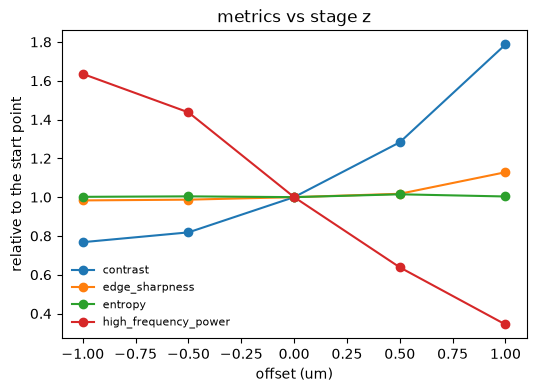

In [ ]:
def plot_response(offsets, rows, unit, unit_name, title):
    fig, ax = plt.subplots(figsize=(6, 4))
    for name in METRICS:
        values = np.array([row[name] for row in rows])
        ax.plot(np.array(offsets) / unit, values / values[len(values) // 2], "o-", label=name)
    ax.set(xlabel=f"offset ({unit_name})", ylabel="relative to the start point", title=title)
    ax.legend(frameon=False, fontsize=8)
    plt.show()


async def response(actuator, offsets):
    """Image at each offset; always back to the start afterwards."""
    await actuator.start()
    rows = []
    try:
        for offset in offsets:
            await actuator.apply(np.atleast_1d(offset).astype(float))
            rows.append(all_metrics((await common.acquire_haadf())[1]))
    finally:
        await actuator.restore()
    return rows


if allowed(ALLOW_STAGE, "z response"):
    step = TEST_TUNING["z"]["step_m"]
    offsets = #[-2 * step, -step, 0.0, step, 2 * step]
    plot_response(offsets, await response(StageZ(), offsets), 1e-6, "um", "metrics vs stage z")

### 3.2 Does the metric respond to C1?
The same scan with the corrector.

In [32]:
TEST_TUNING["C1"]["step_m"]

5e-09

[set_fov] 443.6 -> 186.0 nm
-> ['current'] | run_status: running


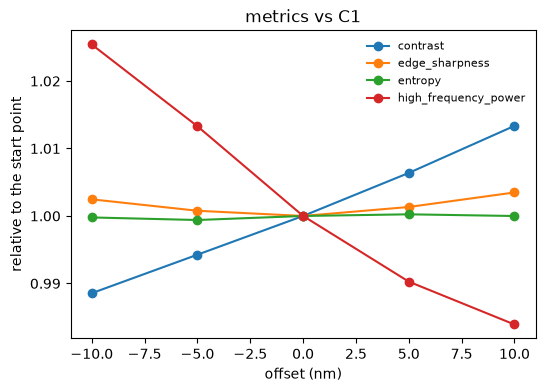

In [29]:
if allowed(ALLOW_CORRECTOR, "C1 response"):
    state = apply(state, await set_fov_node(state))   # C1 / A1 are tuned at the tuning FOV
    step = TEST_TUNING["C1"]["step_m"]
    offsets = [-2 * step, -step, 0.0, step, 2 * step]
    plot_response(offsets, await response(Corrector("C1"), offsets), 1e-9, "nm", "metrics vs C1")

### 3.3 Corrector sign
Uses the corrector's own measurement (`measure_c1a1`) before and after a +5 nm C1 step, then steps back. Compare the C1 values by eye: if C1 changed by **+5 nm** the sign is "adds"; if by **−5 nm** it is "subtracts" (the twin subtracts). The search doesn't need the sign, but you need it to read the results.

On the real CEOS a measurement can take a while; if it times out (30 s), skip this cell.

In [ ]:
if allowed(ALLOW_CORRECTOR, "corrector sign"):
    measure = f"{INSTRUMENTS[INSTRUMENT]['corrector']}_measure_c1a1"
    if measure not in tools:
        print("no", measure, "tool on this server")
    else:
        c1 = Corrector("C1")
        print("before:", await session.call_tool(measure))
        await c1.apply(np.array([5e-9]))
        print("after +5 nm:", await session.call_tool(measure))
        await c1.restore()
        print("after restore:", await session.call_tool(measure))

### 3.4 Beam x/y order
Takes a fresh overview, finds the largest particle and a background point, then takes EDS at both with each beam order. The right order shows **much more signal on the particle than on the background**:
- real microscope: total counts
- twin: the largest element fraction

The configured value is `INSTRUMENTS[INSTRUMENT]["beam_order"]`; the real one is still unverified.

In [ ]:
def signal(record):
    values = np.load(record["npy_path"])
    return float(values.max()) if record.get("elements") else float(values.sum())


if allowed(ALLOW_BEAM, "beam order check"):
    state = apply(state, await set_fov_node(state))
    probe = apply(state, await overview_node(state))
    overview = tiled_io.read_image(probe["overview"]["tiled_key"])
    labels, particles = segment(overview, fov_m=probe["overview"]["fov_m"])
    if not particles:
        raise SystemExit("no particle in this overview: move to an area with particles and re-run")
    smooth_background = np.unravel_index(np.argmin(overview), overview.shape)
    points = [{"id": 1, "row": particles[0]["row"], "col": particles[0]["col"]},
              {"id": 2, "row": float(smooth_background[0]), "col": float(smooth_background[1])}]
    plot_particles(overview, labels, points[:1], "1 = particle (background = darkest pixel)")
    results = {}
    for order in ("col_row", "row_col"):
        t0 = time.time()
        update = await eds_node({**probe, "particles": points,
                                 "settings": {**SETTINGS, "beam_order": order}})
        particle, background = (signal(r) for r in update["spectra"])
        results[order] = particle / max(background, 1e-12)
        print(f"{order}: particle {particle:.3g}, background {background:.3g}, "
              f"ratio {results[order]:.2f} ({(time.time() - t0) / 2:.1f} s per spectrum)")
    best = max(results, key=results.get)
    print(f"-> beam order looks like {best!r}; configured {INSTRUMENTS[INSTRUMENT]['beam_order']!r}")

## Level 4 · Tuning, one protocol step per cell
Each cell runs one named step of the protocol (`tune_node(one_step(state, name))`, so a switched-off cell never runs the next step): `QuadraticSearch` with the small `TEST_TUNING` values, ends at the best point, saves `tune_<name>.json` and `.png` in the run folder. On error it restores that step's start value.

### 4.1 Focus (stage z)

In [11]:
if allowed(ALLOW_STAGE, "focus z"):
    _, start_image = await common.acquire_haadf()
    state = apply(state, await tune_node(one_step(state, "z")))
    if "z" in state.get("tuning", {}):
        result = state["tuning"]["z"]
        show([start_image, tiled_io.read_image(result["best_image_key"])], ["start", "best z"])
        display(Image(result["figure_path"]))

[tune_z]  1 start offset [0.0] um  contrast 0.27577
[tune_z]  2 start offset [-1.999] um  contrast 0.29244
[tune_z]  3 start offset [1.999] um  contrast 0.24876
[tune_z]  4 model offset [-3.998] um  contrast 0.32216
[tune_z]  5 model offset [-6.396] um  contrast 0.3936
[tune_z]  6 model offset [-9.276] um  contrast 0.4932
[tune_z]  7 model offset [-12.736] um  contrast 0.35415
[tune_z]  8 model offset [-9.919] um  contrast 0.42524
[tune_z]  9 model offset [-10.031] um  contrast 0.42629
[tune_z] 10 model offset [-10.136] um  contrast 0.42625
[tune_z] 11 model offset [-9.891] um  contrast 0.42647
[tune_z] 12 model offset [-9.674] um  contrast 0.43499
[tune_z] 13 model offset [-9.534] um  contrast 0.44458
[tune_z] 14 model offset [-9.443] um  contrast 0.44561
[tune_z] best [-9.276] um, contrast 0.4932, 14 images, stop: converged
[tune_z] FAILED: 'current'
-> ['errors', 'run_status'] | run_status: failed
ERROR: tune_z: KeyError: 'current'


In [12]:
print(state.get("run_status"), state.get("errors"))

failed ["tune_z: KeyError: 'current'", "tune_z: KeyError: 'current'"]


### 4.2 C1 (the step sets the tuning FOV itself)

[set_fov] 186.0 -> 186.0 nm
-> ['current'] | run_status: running
[tune_C1]  1 start offset [0.0] nm  contrast 0.3946
[tune_C1]  2 start offset [-20.0] nm  contrast 0.39466
[tune_C1]  3 start offset [20.0] nm  contrast 0.39498
[tune_C1]  4 model offset [40.0] nm  contrast 0.39432
[tune_C1]  5 model offset [7.0] nm  contrast 0.39524
[tune_C1]  6 model offset [6.746] nm  contrast 0.39488
[tune_C1]  7 model offset [6.588] nm  contrast 0.39545
[tune_C1]  8 model offset [7.141] nm  contrast 0.39511
[tune_C1]  9 model offset [7.203] nm  contrast 0.39622
[tune_C1] 10 model offset [7.69] nm  contrast 0.39608
[tune_C1] 11 model offset [8.008] nm  contrast 0.39601
[tune_C1] best [7.203] nm, contrast 0.39622, 11 images, stop: converged
-> ['current', 'tuning'] | run_status: running


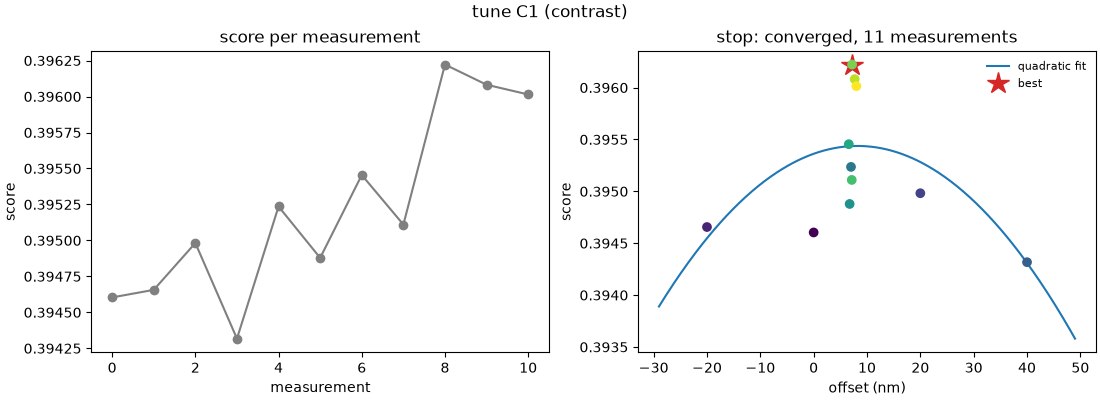

In [20]:
if allowed(ALLOW_CORRECTOR, "tune C1"):
    state = apply(state, await tune_node(one_step(state, "C1")))
    if "C1" in state.get("tuning", {}):
        display(Image(state["tuning"]["C1"]["figure_path"]))

[overview] stem_image_HAADF_20261105T154912436667.h5 (512, 512) -> overview.png
-> ['overview'] | run_status: running
opened
[status_start] stage [-2.94e-05, +4.86e-05, +6.69e-05, +0.00568, +0] | FOV 1.8599999407342693e-07 m | devices 8 (all ON) | ready True
-> ['current', 'start'] | run_status: running


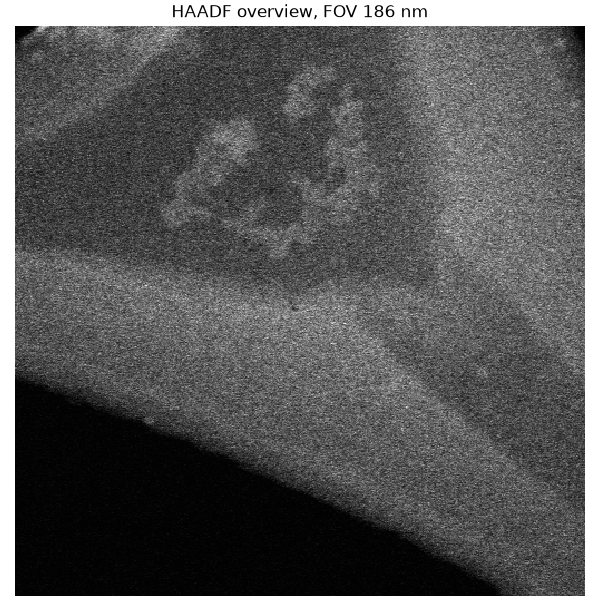

In [19]:
state = apply(state, await overview_node(state))
state = apply(state, await status_node(state)) 
Image(state["overview"]["preview_path"])

### 4.3 A1

[tune_A1]  1 start offset [0.0, 0.0] nm  contrast 0.41572
[tune_A1]  2 start offset [1.0, 0.0] nm  contrast 0.41562
[tune_A1]  3 start offset [0.707, 0.707] nm  contrast 0.41605
[tune_A1]  4 start offset [0.0, 1.0] nm  contrast 0.41614
[tune_A1]  5 start offset [-0.707, 0.707] nm  contrast 0.41611
[tune_A1]  6 start offset [-1.0, 0.0] nm  contrast 0.41566
[tune_A1]  7 start offset [-0.707, -0.707] nm  contrast 0.417
[tune_A1]  8 start offset [-0.0, -1.0] nm  contrast 0.41578
[tune_A1]  9 start offset [0.707, -0.707] nm  contrast 0.41572
[tune_A1] 10 model offset [-1.307, -1.507] nm  contrast 0.41695
[tune_A1] 11 model offset [-1.048, -1.26] nm  contrast 0.41596
[tune_A1] 12 model offset [-0.929, -1.066] nm  contrast 0.41632
[tune_A1] 13 model offset [-0.851, -0.941] nm  contrast 0.41559
[tune_A1] 14 model offset [-0.801, -0.859] nm  contrast 0.41667
[tune_A1] 15 model offset [-0.768, -0.806] nm  contrast 0.41616
[tune_A1] 16 model offset [-0.747, -0.771] nm  contrast 0.41578
[tune_A1] 

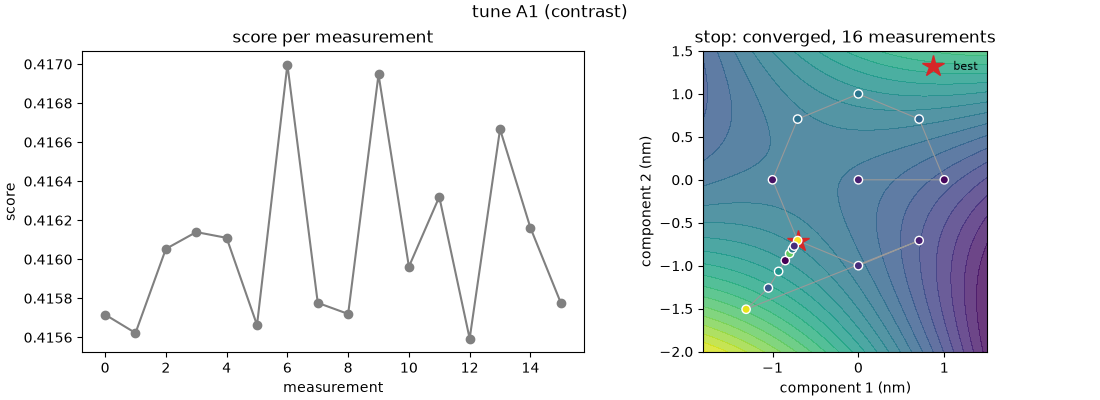

In [13]:
if allowed(ALLOW_CORRECTOR, "tune A1"):
    state = apply(state, await tune_node(one_step(state, "A1")))
    if "A1" in state.get("tuning", {}):
        display(Image(state["tuning"]["A1"]["figure_path"]))

### 4.4 Put the tuning back (optional)
Returns z, C1 and A1 to where they were at the first snapshot. Use it if you want the microscope exactly as before.

In [ ]:
if allowed(ALLOW_STAGE and ALLOW_CORRECTOR, "undo all tuning"):
    await common.move_stage(z=state["snapshots"][0]["stage"][2])
    for name, key in (("C1", "c1_offset_m"), ("A1", "a1_offset_m")):
        total = np.atleast_1d(state["current"].get(key, 0.0))
        if np.any(total):
            corrector = Corrector(name)
            corrector.total = total
            await corrector.restore()
    print("z, C1 and A1 back at the first-snapshot values")

## Level 5 · Segmentation and EDS

### 5.1 Overview and segmentation

[set_fov] 186.0 -> 186.0 nm
-> ['current'] | run_status: no_particles
[overview] stem_image_HAADF_20261105T085843163500.h5 (512, 512) -> overview.png
-> ['overview'] | run_status: no_particles
[segment] 49 particles (52 objects incl. edge ones), FOV 186 nm, image (512, 512)
-> ['particles', 'segmentation'] | run_status: no_particles


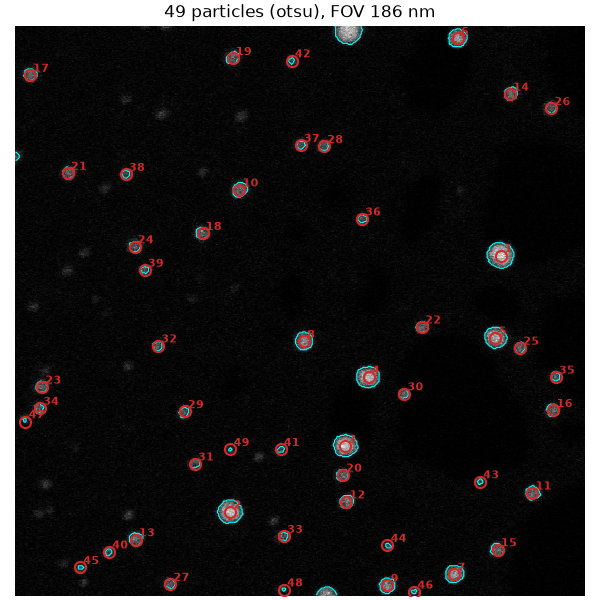

In [40]:
state = apply(state, await set_fov_node(state))
state = apply(state, await overview_node(state))
state = apply(state, await sam_segment_node(state))
Image(state["segmentation"]["overlay_path"])

### 5.2 Try other SAM settings (no new image, no new SAM run)
The same SAM masks, cleaned with other settings. Pick the one that gives one outline per particle, then keep it in `SETTINGS["sam"]`.
`min_visible`: share of a mask that must stay visible to count (lower keeps clusters as one particle); `min_diameter_nm`: drop smaller particles.

In [ ]:
overview = tiled_io.read_image(state["overview"]["tiled_key"])
raw, areas = tiled_io.read_labels(state["segmentation"]["labels_key"])
pixel_m = pixel_size_m(state["overview"]["fov_m"], overview.shape)
for options in ({"min_visible": 0.5},
                {"min_visible": 0.3},
                {"min_visible": 0.5, "min_diameter_nm": 3.0}):
    labels, particles = sam_particles(raw, areas, pixel_m, **options)
    display(plot_particles(overview, labels, particles, f"{options}: {len(particles)} particles"))
# SETTINGS["sam"] = {"min_visible": 0.5, "min_diameter_nm": 3.0}

### 5.3 EDS on the first particles
At most `MAX_EDS_POINTS` spectra.

[eds] 49 particles, measuring the first 3
[eds] particle 1 at beam (0.852, 0.402): 4096 values, max 31
[eds] particle 2 at beam (0.377, 0.852): 4096 values, max 36
[eds] particle 3 at beam (0.578, 0.736): 4096 values, max 30
-> ['spectra'] | run_status: no_particles


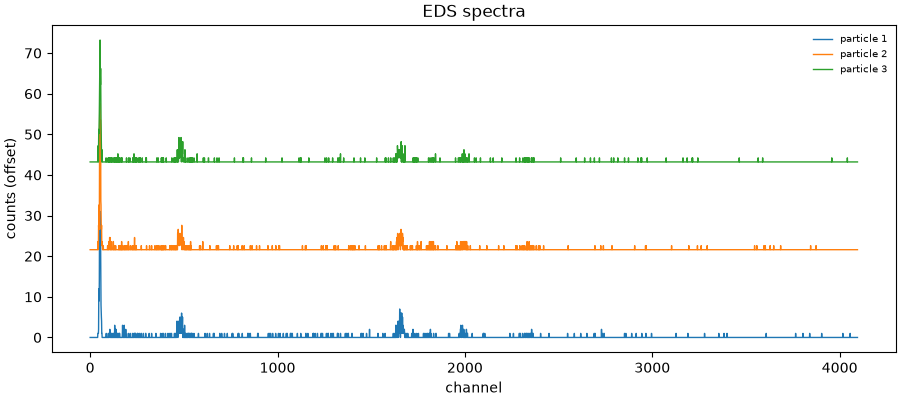

In [41]:
if allowed(ALLOW_BEAM, "EDS on particles"):
    state = apply(state, await eds_node(state))
    display(Image(Path(state["run"]["run_dir"]) / "eds.png"))

### Close the hand-made run
Final snapshot and save: the same record a graph run leaves.

opened
[status_end] stage [-0.00011, +1.69e-05, -0.000106, +0.00519, +0] | FOV 1.8599999407342693e-07 m | devices 8 (all ON) | ready True
-> ['end'] | run_status: no_particles
[save] run_status no_particles | 1 error(s) | /Users/borisslautin/Documents/GitHub/STEM_Particle_Analysis/runs/20261105_083835_real_tests/summary.json
-> ['errors', 'finished', 'run_status', 'summary_path'] | run_status: no_particles


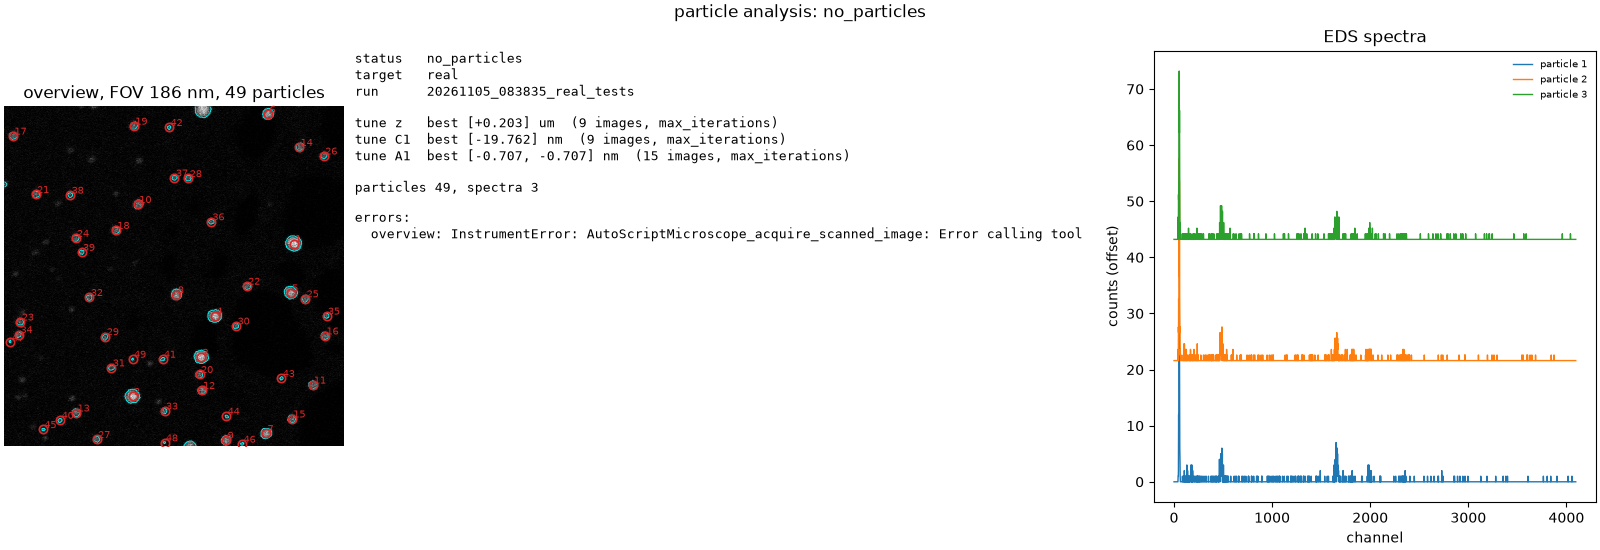

In [42]:
state = apply(state, await status_node(state))
state = apply(state, await save_node(state))
Image(Path(state["run"]["run_dir"]) / "summary.png")

## Level 6 · Build your own graph
Every node is a plain async function `state -> update`, so any order works. Use this to try a partial workflow on the microscope.

The example: **overview → segment → EDS**, with no tuning. It has the same safety pattern as the full graph: a router after each node jumps to `status_end` on failure or when no particles are found, and `status_end → save` always run.

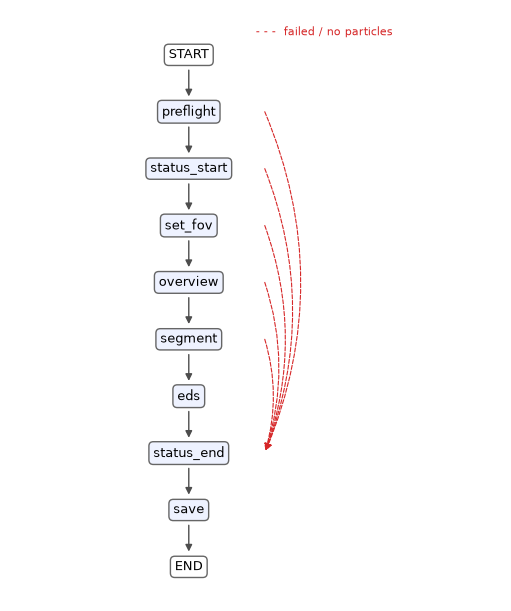

In [44]:
from langgraph.graph import END, START, StateGraph

from stem_agent.states.experiment_state import ParticleRunState


def next_or_stop(next_node):
    """Router: go on, or jump to status_end when the run failed or found no particles."""
    def route(state):
        return "status_end" if state.get("run_status") in ("failed", "no_particles") else next_node
    return route


steps = [("preflight", preflight_node),
         ("status_start", status_node),
         ("set_fov", set_fov_node),
         ("overview", overview_node),
         ("segment", sam_segment_node),
         ("eds", eds_node)]                     # add / remove / reorder nodes here

builder = StateGraph(ParticleRunState)
for name, node in steps:
    builder.add_node(name, node)
builder.add_node("status_end", status_node)
builder.add_node("save", save_node)

builder.add_edge(START, steps[0][0])
for (name, _), (next_name, _) in zip(steps, steps[1:]):
    builder.add_conditional_edges(name, next_or_stop(next_name), [next_name, "status_end"])
builder.add_edge(steps[-1][0], "status_end")
builder.add_edge("status_end", "save")
builder.add_edge("save", END)

my_graph = builder.compile()
plot_graph(my_graph)

In [ ]:
needs_beam = any(name == "eds" for name, _ in steps)
if allowed(ALLOW_BEAM or not needs_beam, "custom graph (it takes EDS spectra)"):
    my_state = await my_graph.ainvoke({"settings": {**SETTINGS, "run_tag": "custom_graph"}})
    print("run_status:", my_state["run_status"], "| errors:", my_state.get("errors") or "none")
    display(Image(Path(my_state["run"]["run_dir"]) / "summary.png"))

## Level 7 · Full run
The whole graph (`particle_graph.run`) with the protocol in `SETTINGS` (small `TEST_TUNING` values), at the current stage position. It needs all three switches.

In [ ]:
from stem_agent.graphs.particle_graph import build_graph, run

plot_graph(build_graph())

In [ ]:
if allowed(ALLOW_STAGE and ALLOW_CORRECTOR and ALLOW_BEAM, "full run"):
    full = await run({**SETTINGS, "run_tag": "real_full"})
    print("run_status:", full["run_status"], "| errors:", full.get("errors") or "none")
    display(Image(Path(full["run"]["run_dir"]) / "summary.png"))

## Notes for the session log
Write down:
- the tool names, if 1.2 needed fixes
- the alpha / `NaN` result (1.3, 2.4)
- whether the metrics respond (3.1, 3.2) and at which step sizes
- the corrector sign (3.3)
- the beam order (3.4)
- the HAADF and EDS times (1.5, 3.4)

The beam order and any tool-name fixes go into `stem_agent/config.py` (`INSTRUMENTS["real"]`).